In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

data_dir = Path("data")

if not data_dir.exists():
    data_dir = Path("../data")

files = sorted(
    data_dir.glob("uber-raw-data-???14.csv"),
    key = lambda file: datetime.strptime(
        file.stem.replace("uber-raw-data-",""),
        "%b%y"
    )
)

print("Total files:", len(files))

total_row = 0

for file in files:
    df = pd.read_csv(file)
    total_row += len(df)

    print("\nFile:", file.name)
    print("Columns:", df.columns.tolist())
    print(f"Row: {len(df):,}")

print(f"\ntotal_row: {total_row:,} row")

Total files: 6

File: uber-raw-data-apr14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 564,516

File: uber-raw-data-may14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 652,435

File: uber-raw-data-jun14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 663,844

File: uber-raw-data-jul14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 796,121

File: uber-raw-data-aug14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 829,275

File: uber-raw-data-sep14.csv
Columns: ['Date/Time', 'Lat', 'Lon', 'Base']
Row: 1,028,136

total_row: 4,534,327 row


In [97]:
# Data Quality Assessment (check missing value, duplicate ??)
missing_values_total = 0
duplicate_records_total = 0

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    duplicate_rate = (duplicate/len(df) * 100)

    missing_values_total += missing_values_count
    duplicate_records_total += duplicate

    print(file.name, "\n")
    df.info()

    print(f"\nMissing Values:\n{missing_values}")
    print(f"\nDuplicate Records:\n{duplicate:,} ({duplicate_rate:.2f}%)\n")

print(f"Total Missing Values: {missing_values_total:,}")
print(f"Total Duplicate Records: {duplicate_records_total:,} ({(duplicate_records_total/len(df)) * 100:.2f}%)")

uber-raw-data-apr14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  str    
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  str    
dtypes: float64(2), str(2)
memory usage: 17.2 MB

Missing Values:
Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

Duplicate Records:
7,749 (1.37%)

uber-raw-data-may14.csv 

<class 'pandas.DataFrame'>
RangeIndex: 652435 entries, 0 to 652434
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  652435 non-null  str    
 1   Lat        652435 non-null  float64
 2   Lon        652435 non-null  float64
 3   Base       652435 non-null  str    
dtypes: float64(2), str(2)
memory usage: 19.9 MB

Missing Values:
Date/Time    0
Lat

In [114]:
# List check
quality_results = []

for file in files:
    df = pd.read_csv(file)

    missing_values = df.isnull().sum()
    missing_values_count = df.isnull().sum().sum()
    duplicate = df.duplicated().sum()

    quality_results.append({
        "Month": file.stem.split("-")[3],
        "Total Records": len(df),
        "Missing Values": missing_values_count,
        "Duplicate Records": duplicate
    })

quality_df = pd.DataFrame(quality_results)

quality_df["Duplicate Rate"] = (
    quality_df["Duplicate Records"]
    / quality_df["Total Records"] * 100
)

print(quality_df)

   Month  Total Records  Missing Values  Duplicate Records  Duplicate Rate
0  apr14         564516               0               7749        1.372680
1  may14         652435               0              10075        1.544215
2  jun14         663844               0              10686        1.609716
3  jul14         796121               0              14152        1.777619
4  aug14         829275               0              15882        1.915167
5  sep14        1028136               0              24037        2.337920


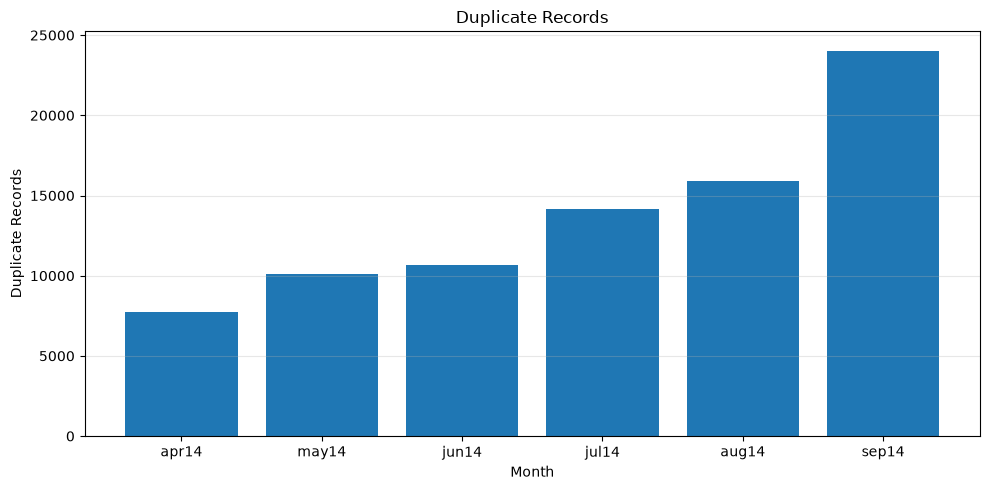

In [120]:
#Uber Duplicate Records by Month
plt.figure(figsize=(10, 5))

plt.bar(
    quality_df["Month"],
    quality_df["Duplicate Records"]
)

plt.title("Duplicate Records")
plt.xlabel("Month")
plt.ylabel("Duplicate Records")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    quality_df["Month"],
    quality_df["Duplicate Rate"],
    marker="o"
)